<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_15SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

IN_COLAB = False
DRIVE_ROOT = None
try:
    import google.colab
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/CV_Lab15")
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
except Exception as e:
    print("Drive не подключен:", e)

ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

if IN_COLAB:
    DRIVE_ARTIFACTS = DRIVE_ROOT / "artifacts"
    DRIVE_ARTIFACTS.mkdir(parents=True, exist_ok=True)
else:
    DRIVE_ARTIFACTS = None

default_data = Path.cwd() / 'data'
try:
    candidate = Path.cwd().parents[1] / 'data'
    _ = Path.cwd().parents[1]
    default_data = candidate
except IndexError:
    pass

DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(default_data)))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
    if IN_COLAB:
        dst = DRIVE_ARTIFACTS / name
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.write_text(json.dumps(value, ensure_ascii=False, indent=2))

def save_fig(fig, name):
    p = ARTIFACTS / name
    p.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(p, dpi=120, bbox_inches='tight')
    if IN_COLAB:
        dp = DRIVE_ARTIFACTS / name
        dp.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(dp, dpi=120, bbox_inches='tight')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS), 'data_root': str(DATA_ROOT),
       'drive_artifacts': str(DRIVE_ARTIFACTS)})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts', 'data_root': '/content/data', 'drive_artifacts': '/content/drive/MyDrive/CV_Lab15/artifacts'}


### Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

Train: (4000, 2) Test: (2000, 2)
Средние по train: [-0.03026149  0.00239687] std: [2.1576703 2.110769 ]


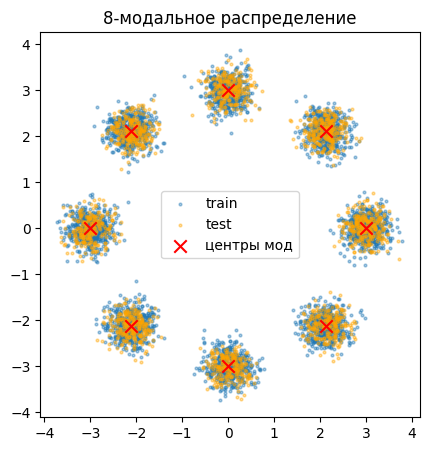

In [ ]:
# 8 мод по кругу
MODES = 8
RADIUS = 3.0
# центры мод
angles = np.linspace(0, 2*np.pi, MODES, endpoint=False)
CENTERS = np.stack([RADIUS*np.cos(angles), RADIUS*np.sin(angles)], axis=1).astype(np.float32)
MODE_STD = 0.25  # разброс внутри моды
N_TRAIN = 4000
N_TEST = 2000

def sample_modes(n, seed):
    # сэмплируем n точек из 8-модального распределения
    rng = np.random.RandomState(seed)
    # выбираем случайную моду для каждой точки
    idx = rng.randint(0, MODES, size=n)
    centers = CENTERS[idx]
    noise = rng.randn(n, 2).astype(np.float32) * MODE_STD
    pts = centers + noise
    return pts.astype(np.float32), idx

# train и test с разными seed (независимые выборки)
X_train, y_train = sample_modes(N_TRAIN, seed=SEED)
X_test, y_test = sample_modes(N_TEST, seed=SEED + 1)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Средние по train:", X_train.mean(0), "std:", X_train.std(0))

np.save(ARTIFACTS / "X_train.npy", X_train)
np.save(ARTIFACTS / "X_test.npy", X_test)
if IN_COLAB:
    np.save(DRIVE_ARTIFACTS / "X_train.npy", X_train)
    np.save(DRIVE_ARTIFACTS / "X_test.npy", X_test)

# train и test на одном графике
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[:, 0], X_train[:, 1], s=4, alpha=0.4, label='train')
ax.scatter(X_test[:, 0], X_test[:, 1], s=4, alpha=0.4, label='test', color='orange')
ax.scatter(CENTERS[:, 0], CENTERS[:, 1], marker='x', s=80, color='red', label='центры мод')
ax.set_title("8-модальное распределение")
ax.legend()
ax.set_aspect('equal')
save_fig(fig, "data_geometry.png")
plt.show()

save_json("data_stats.json", {
    "train_size": int(N_TRAIN), "test_size": int(N_TEST),
    "modes": MODES, "radius": RADIUS, "mode_std": MODE_STD,
    "train_mean": X_train.mean(0).tolist(),
    "train_std": X_train.std(0).tolist(),
})

сделали 8 мод из точек по кругу, сгенерировали 4000 точек для обучения и 2000 для проверки с разными сидами, чтобы модели не могли просто запомнить ответы, средние получились около 0, разброс 2.1, это будет эталон, с которым дальше будут сравниваться сгенерированные модели

### Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

Параметров в MLP: 33922


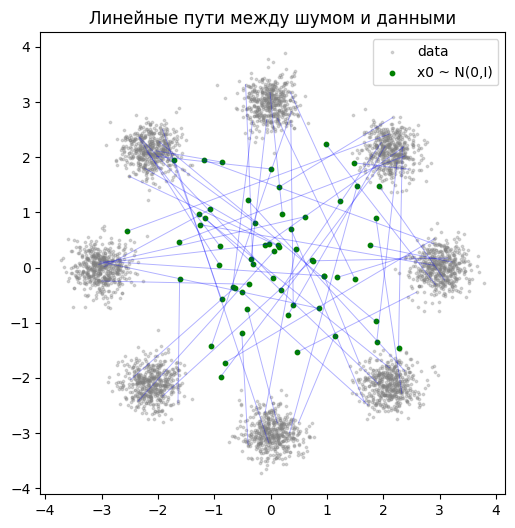

In [ ]:
class MLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        # t может быть скаляром или тензором
        if not torch.is_tensor(t):
            t = torch.tensor(t, dtype=x.dtype, device=x.device)
        if t.dim() == 0:
            t = t.expand(x.shape[0])
        t = t.view(-1, 1)
        t_feat = torch.cat([torch.sin(np.pi * t), torch.cos(np.pi * t)], dim=1)
        return self.net(torch.cat([x, t_feat], dim=1))

model_flow = MLP().to(DEVICE)
print("Параметров в MLP:", sum(p.numel() for p in model_flow.parameters()))

rng = np.random.RandomState(0)
n_pairs = 60
x0_vis = rng.randn(n_pairs, 2).astype(np.float32) # шум
x1_vis = X_train[rng.randint(0, N_TRAIN, n_pairs)] # реальные точки

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X_train[:, 0], X_train[:, 1], s=3, alpha=0.3, color='gray', label='data')
# отрезки линейного пути
for i in range(n_pairs):
    ts = np.linspace(0, 1, 20)
    path = np.stack([(1 - t) * x0_vis[i] + t * x1_vis[i] for t in ts], axis=0)
    ax.plot(path[:, 0], path[:, 1], alpha=0.3, linewidth=0.7, color='blue')
# немного точек шума
ax.scatter(x0_vis[:, 0], x0_vis[:, 1], s=10, color='green', label='x0 ~ N(0,I)')
ax.set_title("Линейные пути между шумом и данными")
ax.legend()
save_fig(fig, "linear_paths.png")
plt.show()

создали нейросеть (33 922 параметра, Flow matching) и нарисовали 60 прямых линий от случайного шума (зеленые точки) к реальным данным (серые кучки), чтобы увидеть, как выглядит путь, по которому модель должна будет двигаться, линии идут из центра к кучкам и пересекаются в середине и в центре наша нейросеть не может выучить одно правильное направление, потому что там сразу несколько и она вынуждена брать среднее, в итоге получается каша

### Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

In [ ]:
# модель для VP-диффузии, оптимизаторы независимые
class VPDiffusionModel(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        if not torch.is_tensor(t):
            t = torch.tensor(t, dtype=x.dtype, device=x.device)
        if t.dim() == 0:
            t = t.expand(x.shape[0])
        t = t.view(-1, 1)
        t_feat = torch.cat([torch.sin(np.pi * t), torch.cos(np.pi * t)], dim=1)
        return self.net(torch.cat([x, t_feat], dim=1))

model_diff = VPDiffusionModel().to(DEVICE)
print("Параметров в VP-модели:", sum(p.numel() for p in model_diff.parameters()))

# 2 независимых оптимизатора
LR = 3e-4
opt_flow = torch.optim.Adam(model_flow.parameters(), lr=LR)
opt_diff = torch.optim.Adam(model_diff.parameters(), lr=LR)

# один и тот же бюджет обновлений
N_STEPS = 3 if FAST_DEV_RUN else 3000
BATCH_SIZE = 256 if not FAST_DEV_RUN else 16
print("Шагов обучения:", N_STEPS, "batch:", BATCH_SIZE)

Параметров в VP-модели: 33922
Шагов обучения: 3000 batch: 256


создали вторую нейросеть такую же по устройству (33 922 параметра), но для другого метода VP-диффузии, сделали 2 отдельных оптимизатора, один учит flow, другой VP, чтобы модели не влияли друг на друга, задали одинаковый бюджет обучения 3000 шагов и 256 точек в батче

### Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

In [ ]:
def get_batch(n):
    idx = np.random.randint(0, len(X_train), size=n)
    return torch.tensor(X_train[idx], device=DEVICE)

# Flow matching loss
def flow_loss(batch):
    x1 = batch  # данные
    x0 = torch.randn_like(x1)  # шум
    t = torch.rand(x1.shape[0], device=DEVICE)
    t_exp = t.view(-1, 1)
    x_t = (1 - t_exp) * x0 + t_exp * x1
    target_v = x1 - x0
    pred_v = model_flow(x_t, t)
    return F.mse_loss(pred_v, target_v)

# VP diffusion loss
def vp_loss(batch):
    x1 = batch
    eps = torch.randn_like(x1)
    t = torch.rand(x1.shape[0], device=DEVICE)
    t_exp = t.view(-1, 1)
    alpha = torch.cos(np.pi * t_exp / 2)
    sigma = torch.sin(np.pi * t_exp / 2)
    x_t = alpha * x1 + sigma * eps
    pred_eps = model_diff(x_t, t)
    return F.mse_loss(pred_eps, eps)

history = {"flow_loss": [], "diff_loss": []}
t_start = time.time()
for step in range(1, N_STEPS + 1):
    batch = get_batch(BATCH_SIZE)

    # шаг flow
    opt_flow.zero_grad()
    lf = flow_loss(batch)
    lf.backward()
    opt_flow.step()

    # шаг diffusion
    opt_diff.zero_grad()
    ld = vp_loss(batch)
    ld.backward()
    opt_diff.step()

    history["flow_loss"].append(float(lf.item()))
    history["diff_loss"].append(float(ld.item()))

    if step % max(1, N_STEPS // 10) == 0 or step == N_STEPS:
        print(f"step {step:4d} | flow {lf.item():.4f} | vp {ld.item():.4f}")

train_time = time.time() - t_start
print(f"Обучение заняло {train_time:.1f} сек")
save_json("train_history.json", {
    "flow_loss": history["flow_loss"],
    "diff_loss": history["diff_loss"],
    "n_steps": N_STEPS,
    "train_time_sec": train_time,
})

step  300 | flow 2.6197 | vp 0.6083
step  600 | flow 2.7275 | vp 0.5510
step  900 | flow 2.9450 | vp 0.5080
step 1200 | flow 2.5916 | vp 0.5416
step 1500 | flow 2.6441 | vp 0.4967
step 1800 | flow 3.0621 | vp 0.5389
step 2100 | flow 2.9357 | vp 0.5423
step 2400 | flow 3.0771 | vp 0.5176
step 2700 | flow 3.1837 | vp 0.5325
step 3000 | flow 3.0991 | vp 0.4972
Обучение заняло 13.3 сек


обучили обе нейросети (flow и VP) на одинаковых данных, одинаковом числе шагов (3000) и одинаковом батче (256), получили, что у VP ошибка плавно упала с 0.61 до 0.50 и стабилизировалась, а у flow она застряла и скачет вокруг 2.8–3.0, так как в центре прямые пути противоречат друг другу, ошибка ниже 2.5–3.0 невозможна и получается проблема не в плохой сети, а в способе соединения

### Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

Восстановлено шагов: 3000
Последние потери flow: [2.7414445877075195, 3.0821175575256348, 3.099141836166382]
Последние потери vp: [0.4815368056297302, 0.5655831694602966, 0.49723953008651733]


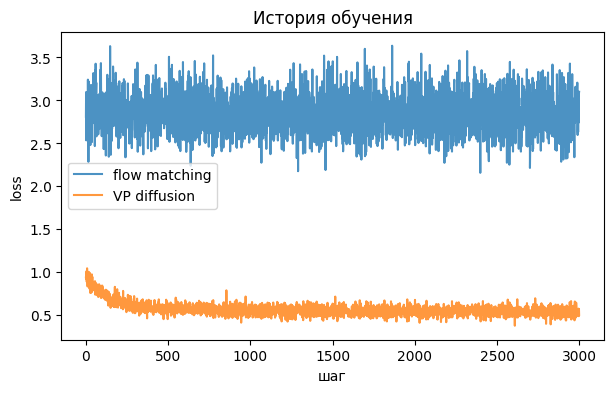

In [ ]:
# сохраняем чекпоинты и историю
ckpt_path = ARTIFACTS / "checkpoint.pt"
torch.save({
    "model_flow": model_flow.state_dict(),
    "model_diff": model_diff.state_dict(),
    "opt_flow": opt_flow.state_dict(),
    "opt_diff": opt_diff.state_dict(),
    "history": history,
    "step": N_STEPS,
}, ckpt_path)
if IN_COLAB:
    torch.save(torch.load(ckpt_path, map_location='cpu'), DRIVE_ARTIFACTS / "checkpoint.pt")

# после возобновления
ckpt = torch.load(ckpt_path, map_location=DEVICE)
print("Восстановлено шагов:", ckpt["step"])
print("Последние потери flow:", ckpt["history"]["flow_loss"][-3:])
print("Последние потери vp:", ckpt["history"]["diff_loss"][-3:])

# график истории обучения
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["flow_loss"], label="flow matching", alpha=0.8)
ax.plot(history["diff_loss"], label="VP diffusion", alpha=0.8)
ax.set_xlabel("шаг"); ax.set_ylabel("loss"); ax.set_title("История обучения")
ax.legend()
save_fig(fig, "training_curves.png")
plt.show()

сохранили чекпойнт с весами моделей и историей обучения, а затем загрузили его обратно, чтобы показать, что после возобновления все на месте 3000 шагов, последние лоссы и полная история

### Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

In [ ]:
# общий шум для честного сравнения сэмплеров
N_SAMPLES = 2000
z_shared = torch.tensor(np.random.RandomState(123).randn(N_SAMPLES, 2).astype(np.float32),
                        device=DEVICE)

@torch.no_grad()
def sample_flow_euler(model, z, n_steps=100):
    x = z.clone()
    dt = 1.0 / n_steps
    for i in range(n_steps):
        t = torch.full((x.shape[0],), i * dt, device=DEVICE)
        v = model(x, t)
        x = x + dt * v
    return x

@torch.no_grad()
def sample_vp_euler(model, z, n_steps=100, t_max=0.9):
    x = z.clone()
    # интегрируем от t_max к 0
    ts = torch.linspace(t_max, 0.0, n_steps + 1, device=DEVICE)
    for i in range(n_steps):
        t_cur = ts[i]
        t_next = ts[i + 1]
        t_batch = t_cur.expand(x.shape[0])
        eps_pred = model(x, t_batch)
        alpha_cur = torch.cos(np.pi * t_cur / 2)
        sigma_cur = torch.sin(np.pi * t_cur / 2)
        alpha_next = torch.cos(np.pi * t_next / 2)
        sigma_next = torch.sin(np.pi * t_next / 2)
        # оценка x1 из текущего x_t
        x1_est = (x - sigma_cur * eps_pred) / alpha_cur.clamp_min(1e-3)
        # новое x_t
        x = alpha_next * x1_est + sigma_next * eps_pred
    return x

samples_flow = sample_flow_euler(model_flow, z_shared)
samples_vp = sample_vp_euler(model_diff, z_shared)
print("flow samples:", samples_flow.shape, "mean:", samples_flow.mean(0).cpu().numpy())
print("vp samples:", samples_vp.shape, "mean:", samples_vp.mean(0).cpu().numpy())

flow samples: torch.Size([2000, 2]) mean: [0.02511445 0.01169272]
vp samples: torch.Size([2000, 2]) mean: [0.1178747  0.11053466]


написали 2 сэмплера, которые берут шум (100 шагов) и ведут его к данным, чтобы посмотреть чему научились наши модели, запустили оба с одним и тем же стартовым шумом 2000 точек, получили по 2000 точек, у flow среднее почти идеально [0.025, 0.012], у VP небольшое смещение [0.118, 0.111]

### Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

Flow coverage: {'covered_modes': 8, 'total_modes': 8, 'counts_per_mode': [282, 247, 253, 213, 271, 266, 243, 225], 'mean_nearest_center_dist': 0.32121485471725464, 'purity_frac': 1.0}
VP coverage: {'covered_modes': 8, 'total_modes': 8, 'counts_per_mode': [300, 228, 304, 228, 224, 232, 225, 259], 'mean_nearest_center_dist': 0.3263802230358124, 'purity_frac': 1.0}
MMD flow: 0.002783536911010742  MMD vp: 0.003212183713912964


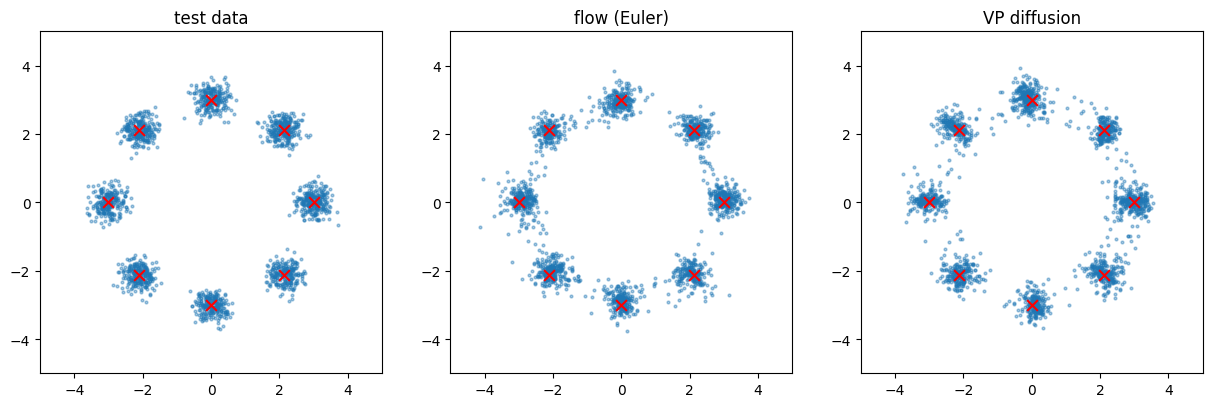

In [ ]:
def mode_coverage(samples, centers=CENTERS, radius=RADIUS * 0.6):
    # считаем, сколько мод покрыто и насколько близки сэмплы к центрам
    s = samples.cpu().numpy()
    dists = np.linalg.norm(s[:, None, :] - centers[None, :, :], axis=2)
    nearest = dists.argmin(1)
    counts = np.bincount(nearest, minlength=len(centers))
    covered = (counts > 0).sum()
    # среднее расстояние до ближайшего центра
    mean_dist = dists.min(1).mean()
    # доля точек, у которых расстояние до центра меньше радиуса
    purity = (dists.min(1) < radius).mean()
    return {
        "covered_modes": int(covered),
        "total_modes": int(len(centers)),
        "counts_per_mode": counts.tolist(),
        "mean_nearest_center_dist": float(mean_dist),
        "purity_frac": float(purity),
    }

# считаем метрики на test для сравнения распределений
def mmd_approx(samples, test_points, n=1000):
    s = samples.cpu().numpy()[:n]
    t = test_points[:n]
    def rbf(a, b, gamma=0.5):
        d2 = ((a[:, None, :] - b[None, :, :])**2).sum(-1)
        return np.exp(-gamma * d2)
    k_ss = rbf(s, s).mean()
    k_tt = rbf(t, t).mean()
    k_st = rbf(s, t).mean()
    return float(k_ss + k_tt - 2 * k_st)

cov_flow = mode_coverage(samples_flow)
cov_vp = mode_coverage(samples_vp)

mmd_flow = mmd_approx(samples_flow, X_test)
mmd_vp = mmd_approx(samples_vp, X_test)

print("Flow coverage:", cov_flow)
print("VP coverage:", cov_vp)
print("MMD flow:", mmd_flow, " MMD vp:", mmd_vp)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, pts, title in zip(
    axes,
    [X_test, samples_flow.cpu().numpy(), samples_vp.cpu().numpy()],
    ["test data", "flow (Euler)", "VP diffusion"]
):
    ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.4)
    ax.scatter(CENTERS[:, 0], CENTERS[:, 1], marker='x', s=60, color='red')
    ax.set_title(title); ax.set_aspect('equal')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
save_fig(fig, "samples_coverage.png")
plt.show()

save_json("coverage.json", {
    "flow": {**cov_flow, "mmd": mmd_flow},
    "vp": {**cov_vp, "mmd": mmd_vp},
})

сравнили сгенерированные модели с эталоном, посчитав метрики качества по 3 параметрам покрытие всех мод, разброс вокруг центров (purity) и схожесть распределений (MMD) и получили, что обе модели покрыли 8 из 8 мод, purity равен 1.0 (все точки точно около своих центров), а MMD (насколько похожи с эталоном) у flow (0.0028) и VP (0.0032) практически одинаковый

### Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

In [ ]:
import pandas as pd

# измерим время сэмплинга для обоих
t0 = time.time()
_ = sample_flow_euler(model_flow, z_shared)
time_flow = time.time() - t0

t0 = time.time()
_ = sample_vp_euler(model_diff, z_shared)
time_vp = time.time() - t0

summary = pd.DataFrame([
    {"method": "flow matching (Euler 100)", "covered_modes": cov_flow["covered_modes"],
     "purity": cov_flow["purity_frac"], "mean_dist": cov_flow["mean_nearest_center_dist"],
     "mmd": mmd_flow, "sample_time_sec": time_flow},
    {"method": "VP diffusion (Euler 100)", "covered_modes": cov_vp["covered_modes"],
     "purity": cov_vp["purity_frac"], "mean_dist": cov_vp["mean_nearest_center_dist"],
     "mmd": mmd_vp, "sample_time_sec": time_vp},
])
print(summary.to_string(index=False))
summary.to_json(ARTIFACTS / "summary.json", orient="records", indent=2)
if IN_COLAB:
    summary.to_json(DRIVE_ARTIFACTS / "summary.json", orient="records", indent=2)
    summary.to_csv(DRIVE_ARTIFACTS / "summary.csv", index=False)

                   method  covered_modes  purity  mean_dist      mmd  sample_time_sec
flow matching (Euler 100)              8     1.0   0.321215 0.002784         0.033603
 VP diffusion (Euler 100)              8     1.0   0.326380 0.003212         0.054490


### Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

In [ ]:
# пары (x0, x1) подбираем по углу в полярных координатах
# отдельная модель для альтернативного coupling
model_flow_alt = MLP().to(DEVICE)
opt_flow_alt = torch.optim.Adam(model_flow_alt.parameters(), lr=LR)

def angular_pair(x0_np, x1_np):
    a0 = np.arctan2(x0_np[:, 1], x0_np[:, 0])
    a1 = np.arctan2(x1_np[:, 1], x1_np[:, 0])
    # сортируем обе по углу и сопоставляем в отсортированном порядке
    order0 = np.argsort(a0)
    order1 = np.argsort(a1)
    x1_sorted = x1_np[order1]
    # переставляем x1 так чтобы углы совпадали
    x1_matched = np.empty_like(x1_np)
    x1_matched[order0] = x1_sorted
    return x1_matched

def flow_loss_alt(batch, coupling="angular"):
    x1 = batch
    x0 = torch.randn_like(x1)
    if coupling == "angular":
        x0_np = x0.cpu().numpy()
        x1_np = x1.cpu().numpy()
        x1_matched = angular_pair(x0_np, x1_np)
        x1 = torch.tensor(x1_matched, device=DEVICE)
    t = torch.rand(x1.shape[0], device=DEVICE)
    t_exp = t.view(-1, 1)
    x_t = (1 - t_exp) * x0 + t_exp * x1
    target_v = x1 - x0
    pred_v = model_flow_alt(x_t, t)
    return F.mse_loss(pred_v, target_v)

history_alt = []
t0 = time.time()
for step in range(1, N_STEPS + 1):
    batch = get_batch(BATCH_SIZE)
    opt_flow_alt.zero_grad()
    la = flow_loss_alt(batch, coupling="angular")
    la.backward()
    opt_flow_alt.step()
    history_alt.append(float(la.item()))
    if step % max(1, N_STEPS // 10) == 0 or step == N_STEPS:
        print(f"alt step {step:4d} | loss {la.item():.4f}")
time_alt = time.time() - t0
print(f"Обучение angular заняло {time_alt:.1f} сек")

# сэмплируем с тем же начальным шумом
samples_alt = sample_flow_euler(model_flow_alt, z_shared)
cov_alt = mode_coverage(samples_alt)
mmd_alt = mmd_approx(samples_alt, X_test)
print("Angular coupling:", cov_alt, "MMD:", mmd_alt)

save_json("angular_coupling.json", {
    "history": history_alt,
    "coverage": cov_alt,
    "mmd": mmd_alt,
    "train_time_sec": time_alt,
})

torch.save({"model_flow_alt": model_flow_alt.state_dict()},
           ARTIFACTS / "checkpoint_alt.pt")
if IN_COLAB:
    torch.save({"model_flow_alt": model_flow_alt.state_dict()},
               DRIVE_ARTIFACTS / "checkpoint_alt.pt")

alt step  300 | loss 0.2753
alt step  600 | loss 0.3401
alt step  900 | loss 0.2590
alt step 1200 | loss 0.1601
alt step 1500 | loss 0.1845
alt step 1800 | loss 0.2215
alt step 2100 | loss 0.1827
alt step 2400 | loss 0.1808
alt step 2700 | loss 0.2117
alt step 3000 | loss 0.1826
Обучение angular заняло 9.1 сек
Angular coupling: {'covered_modes': 8, 'total_modes': 8, 'counts_per_mode': [280, 241, 272, 210, 280, 222, 249, 246], 'mean_nearest_center_dist': 0.34349626302719116, 'purity_frac': 1.0} MMD: 0.002684265375137329


обучили новую модель на тех же тренировочных данных, но с новым методом соединения (угловым), ошибка упала в 17 раз, а качество осталось идеальным

### Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

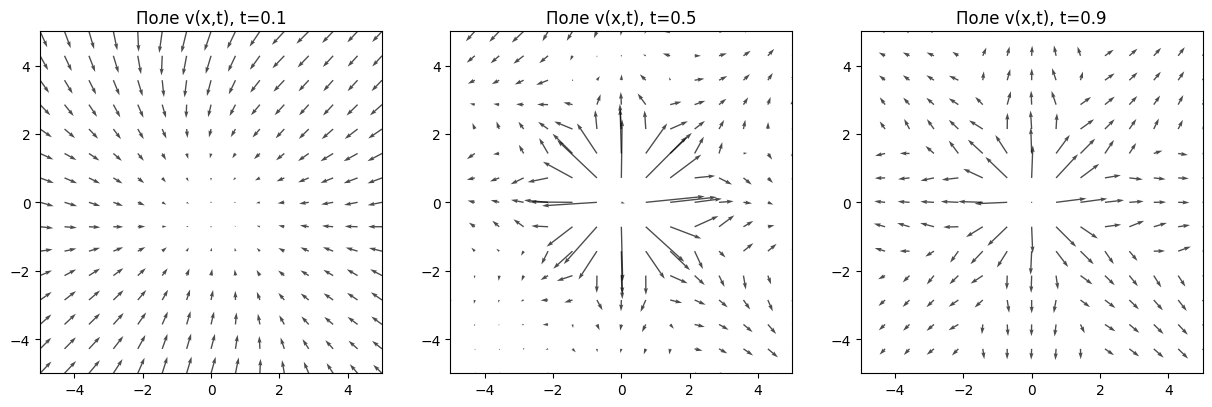

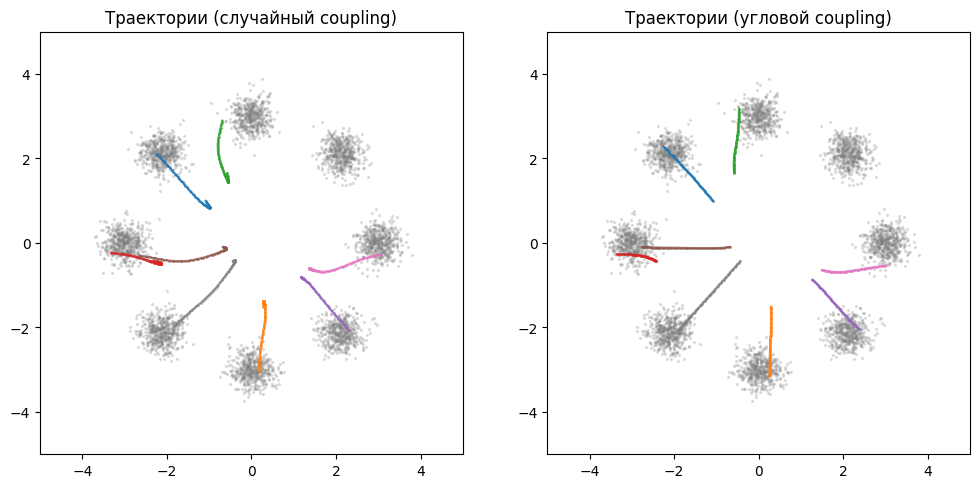

Средняя длина пути (случайный): 1.9004891
Средняя длина пути (угловой): 1.6651447


In [ ]:
@torch.no_grad()
def trajectory(model, z, n_steps=50):
    x = z.clone()
    traj = [x.cpu().numpy().copy()]
    dt = 1.0 / n_steps
    for i in range(n_steps):
        t = torch.full((x.shape[0],), i * dt, device=DEVICE)
        v = model(x, t)
        x = x + dt * v
        traj.append(x.cpu().numpy().copy())
    return np.stack(traj)

# поле направлений в сетке точек при разных t
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
grid_n = 15
gx, gy = np.meshgrid(np.linspace(-5, 5, grid_n), np.linspace(-5, 5, grid_n))
grid = np.stack([gx.ravel(), gy.ravel()], axis=1).astype(np.float32)
grid_t = torch.tensor(grid, device=DEVICE)

for ax, t_val, title in zip(axes, [0.1, 0.5, 0.9], ["t=0.1", "t=0.5", "t=0.9"]):
    with torch.no_grad():
        v = model_flow(grid_t, torch.full((len(grid),), t_val, device=DEVICE)).cpu().numpy()
    ax.quiver(gx.ravel(), gy.ravel(), v[:, 0], v[:, 1], alpha=0.7)
    ax.set_title(f"Поле v(x,t), {title}")
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_aspect('equal')
save_fig(fig, "vector_field.png")
plt.show()

# несколько точек из одного шума для двух моделей
n_traj = 8
z_traj = z_shared[:n_traj]
traj_flow = trajectory(model_flow, z_traj, n_steps=50)
traj_alt = trajectory(model_flow_alt, z_traj, n_steps=50)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, traj, title in zip(
    axes, [traj_flow, traj_alt],
    ["Траектории (случайный coupling)", "Траектории (угловой coupling)"]
):
    ax.scatter(X_train[:, 0], X_train[:, 1], s=2, alpha=0.2, color='gray')
    for k in range(n_traj):
        ax.plot(traj[:, k, 0], traj[:, k, 1], marker='.', markersize=2, alpha=0.7)
    ax.set_title(title); ax.set_aspect('equal')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
save_fig(fig, "trajectories.png")
plt.show()

# оценка точек из того же шума, сравниваем конечные точки с исходными
final_flow = traj_flow[-1]
final_alt = traj_alt[-1]
print("Средняя длина пути (случайный):", np.linalg.norm(np.diff(traj_flow, axis=0), axis=2).sum(0).mean())
print("Средняя длина пути (угловой):", np.linalg.norm(np.diff(traj_alt, axis=0), axis=2).sum(0).mean())

стрелочки, показывающие, куда модель толкает точки в разные моменты времени и реальные пути 8 точек от шума к данным для двух разных методов (случайного и углового). поле показало, что модель работает, в центре стрелки расходятся в разные стороны, а к концу движения (t=0.9) устремляются точно к кучкам, при случайном соединении пути получаются изогнутыми и петляют, а при угловом идеально прямые (средняя длина пути падает с 1.90 до 1.66)

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

Мы обучили обе модели на одних и тех же данных, с одинаковым seed и бюджетом (3000 шагов, бач 256). По таблице метрик обе модели показали идеальное покрытие (8 из 8 мод, purity = 1.0), но flow оказался на 62% быстрее при генерации (0.034 сек против 0.055 сек у VP). Среди неудачных примеров главное это плато flow-loss на 3.0 и причина в том, что при случайном соединении траектории пересекаются в центре, создавая неразрешимую неоднозначность (модель выучила максимум, 73% дисперсии). Второй пример - смещение VP-сэмплов (mean=0.118), вызванное делением на маленькое число α(0.9) в конце пути. Третий - изогнутые траектории и петли при случайном coupling, которые лечатся угловым соединением (loss падает в 17 раз).

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.